<a href="https://colab.research.google.com/github/ust-buan-640/buan-640-notebooks/blob/main/notebooks/m11-7-intervals.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Estimating a mean and predicting one home

The line gives one number for a home of a given size. This notebook puts an interval around that number, and the interval depends on which question we are asking.

*Data: Ames housing data (De Cock, 2011, Journal of Statistics Education), single-family homes in the North Ames neighborhood sold under normal conditions in 2007. `area` is the above-ground living area in square feet, and `price` is the sale price in dollars.*

The same three steps as before: libraries, data, model.

In [1]:
# @title
import pandas as pd
import statsmodels.api as sm

homes = pd.read_csv("https://raw.githubusercontent.com/ust-buan-640/buan-640-notebooks/main/data/north_ames_2007.csv")
model = sm.formula.ols("price ~ area", data=homes).fit()

In [2]:
# @title Setup for the illustrations (colors and helper functions)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import scipy.stats as stats
from matplotlib.patches import FancyBboxPatch

PURPLE, GOLD, GRAY, LIGHT, SAND = "#510C76", "#B07A00", "#6E6E6E", "#C9B8D6", "#EFE3C2"
plt.rcParams.update({"font.size": 14, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#444444", "axes.labelcolor": "#222222",
                     "xtick.color": "#444444", "ytick.color": "#444444",
                     "axes.titlesize": 14, "legend.fontsize": 12})
DOLLARS = mtick.FuncFormatter(lambda v, p: "$0" if v == 0 else ("−" if v < 0 else "") + f"${abs(v)/1000:,.0f}K")


def fit(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    b1 = np.sum((x - x.mean()) * (y - y.mean())) / np.sum((x - x.mean()) ** 2)
    return y.mean() - b1 * x.mean(), b1


def home_axes(ax, xlim=(700, 2400), ylim=(0, 290000)):
    ax.set_xlim(*xlim); ax.set_ylim(*ylim)
    ax.yaxis.set_major_formatter(DOLLARS)
    ax.set_xlabel("living area (sq ft)"); ax.set_ylabel("sale price")


na = pd.read_csv("https://raw.githubusercontent.com/ust-buan-640/buan-640-notebooks/main/data/north_ames_2007.csv")
x, y = na.area.values.astype(float), na.price.values.astype(float)
b0, b1 = fit(x, y)
yhat = b0 + b1 * x
res = y - yhat
XS = np.linspace(700, 2400, 100)
n = len(x)
xbar = x.mean()
ssxx = np.sum((x - xbar) ** 2)
s = np.sqrt(np.sum(res ** 2) / (n - 2))


def box(ax, cx, cy, w, h, text, ec=PURPLE, fc="white", fs=13):
    ax.add_patch(FancyBboxPatch((cx - w / 2, cy - h / 2), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=fc, ec=ec, lw=1.6))
    ax.text(cx, cy, text, ha="center", va="center", fontsize=fs)

def arrow(ax, p, q, color=PURPLE):
    ax.annotate("", xy=q, xytext=p, arrowprops=dict(arrowstyle="-|>", color=color, lw=1.6))

plt.rcParams["figure.dpi"] = 110

## Two questions about 1,500 square feet

- **Average:** what do 1,500 sq ft homes in North Ames sell for, on average?
- **One home:** what will this particular 1,500 sq ft home sell for?

Both start from the same point on the line:

$$\hat{y}^* = 65{,}364 + 63.94(1{,}500) = \$161{,}282$$

Same point estimate, different uncertainty.

## Why one home is harder to predict

For the average, the only error comes from not knowing the true line exactly, and more data shrinks it. For one home, there is the same error plus the home's own $\varepsilon$: its condition, its buyer, its luck. No amount of data removes that part.

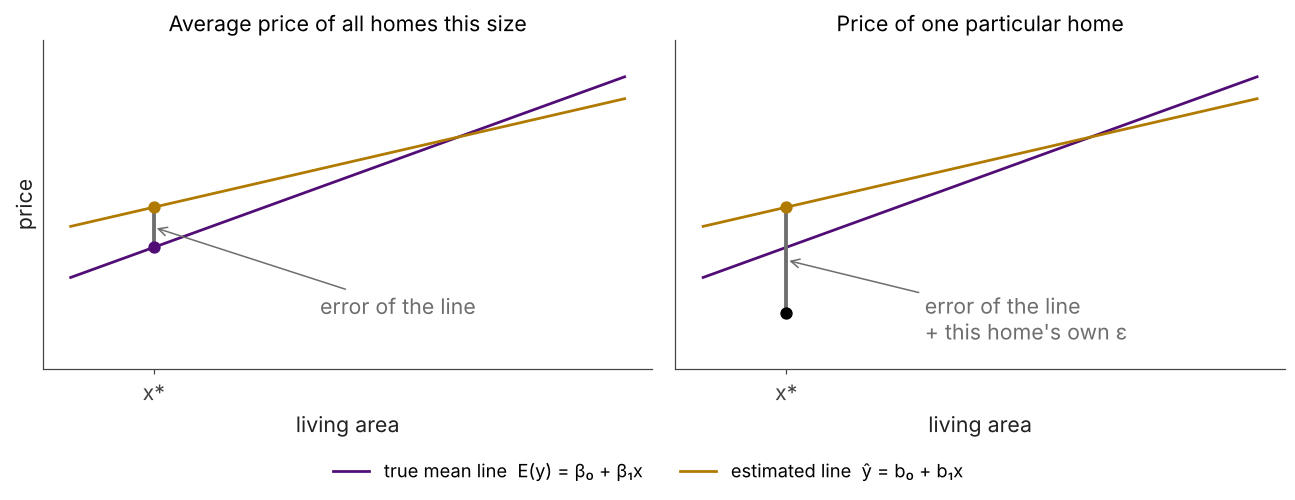

In [3]:
# @title Show the plotting code
# ---------------- 9. intervals ----------------
fig, axs = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
true = lambda v: 2 + 0.55 * v; est = lambda v: 3.4 + 0.35 * v; xs0 = 1.5
X10 = np.linspace(0, 10, 20)
for jdx, ax in enumerate(axs):
    ax.plot(X10, true(X10), color=PURPLE, lw=1.8, label="true mean line  E(y) = β₀ + β₁x")
    ax.plot(X10, est(X10), color=GOLD, lw=1.8, label="estimated line  ŷ = b₀ + b₁x")
    ax.scatter([xs0], [est(xs0)], color=GOLD, s=50, zorder=3)
    if jdx == 0:
        ax.scatter([xs0], [true(xs0)], color=PURPLE, s=50, zorder=3)
        ax.plot([xs0, xs0], [true(xs0), est(xs0)], color=GRAY, lw=2.5)
        ax.set_title("Average price of all homes this size")
        ax.annotate("error of the line", xy=(xs0, (true(xs0) + est(xs0)) / 2), xytext=(4.5, 1.0), color=GRAY,
                    arrowprops=dict(arrowstyle="->", color=GRAY))
    else:
        yind = true(xs0) - 1.8
        ax.scatter([xs0], [yind], color="black", s=50, zorder=3)
        ax.plot([xs0, xs0], [yind, est(xs0)], color=GRAY, lw=2.5)
        ax.set_title("Price of one particular home")
        ax.annotate("error of the line\n+ this home's own ε", xy=(xs0, (yind + est(xs0)) / 2), xytext=(4.0, 0.3), color=GRAY,
                    arrowprops=dict(arrowstyle="->", color=GRAY))
    ax.set_xticks([xs0]); ax.set_xticklabels(["x*"]); ax.set_yticks([]); ax.set_xlabel("living area"); ax.set_ylim(-0.5, 8.5)
axs[0].set_ylabel("price")
h_, l_ = axs[0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.08))
fig.tight_layout(); plt.show()  # f33_two_errors.png

## Interval formulas

Confidence interval for the mean of $y$ at $x^*$:

$$\hat{y}^* \pm t_{\alpha/2}\, s_{\hat{y}^*}, \qquad s_{\hat{y}^*} = s_e\sqrt{\frac{1}{n} + \frac{(x^* - \bar{x})^2}{\sum (x_i - \bar{x})^2}}$$

Prediction interval for one new $y$ at $x^*$:

$$\hat{y}^* \pm t_{\alpha/2}\, s_{pred}, \qquad s_{pred} = s_e\sqrt{1 + \frac{1}{n} + \frac{(x^* - \bar{x})^2}{\sum (x_i - \bar{x})^2}}$$

Both use $t$ with $n - 2$ degrees of freedom. The only difference is the 1 under the square root: the variance of the new home's own error.

## North Ames, 1,500 square feet

| | Average of all 1,500 sq ft homes | One 1,500 sq ft home |
|---|---|---|
| Standard error | \$2,471 | \$18,110 |
| 95% interval ($t$ = 1.988) | \$156,370 to \$166,193 | \$125,285 to \$197,278 |

*We are 95% confident that the average sale price of 1,500 sq ft homes in North Ames is between \$156,000 and \$166,000.*

*We are 95% confident that a particular 1,500 sq ft home will sell for between \$125,000 and \$197,000.*

## In Python

`get_prediction()` gives both intervals: `mean_ci` is the confidence interval for the average, and `obs_ci` is the prediction interval for one home. Excel's ToolPak does not compute either interval.

In [4]:
# @title
new_homes = pd.DataFrame({"area": [1500]})
model.get_prediction(new_homes).summary_frame(alpha=0.05)

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,161281.56407,2470.970052,156370.243531,166192.884609,125285.121946,197278.006194


## Intervals along the line

Both intervals are narrowest at $\bar{x}$ and widen as $x^*$ moves away from it. The prediction interval is always wider, and it would not shrink much even with thousands of homes, because it includes each home's own error.

Neither interval protects against extrapolation. Both formulas assume the straight line still holds at $x^*$, which the data can check only within the range of sizes we observed, 858 to 2,223 square feet.

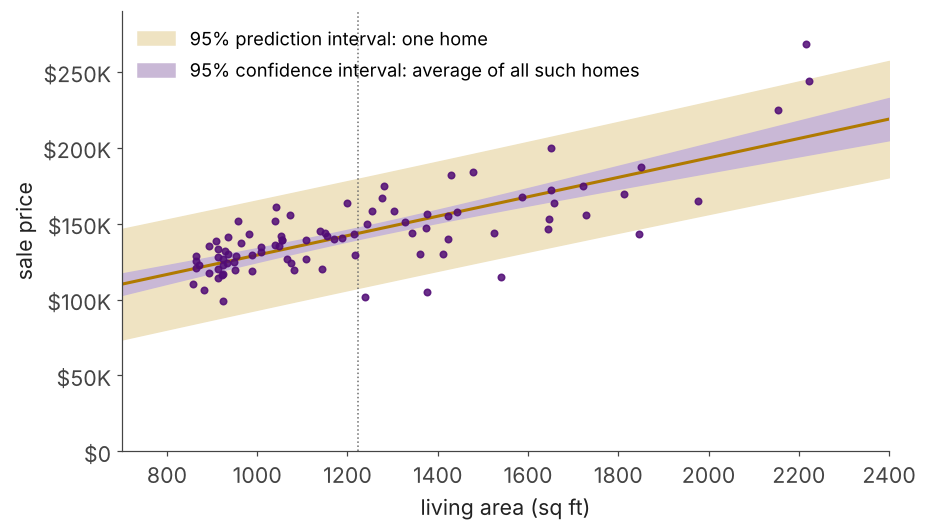

In [5]:
# @title Show the plotting code
tcrit = stats.t.ppf(0.975, n - 2)
se_m = s * np.sqrt(1 / n + (XS - xbar) ** 2 / ssxx); se_p = s * np.sqrt(1 + 1 / n + (XS - xbar) ** 2 / ssxx)
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.fill_between(XS, b0 + b1 * XS - tcrit * se_p, b0 + b1 * XS + tcrit * se_p, color=SAND, label="95% prediction interval: one home")
ax.fill_between(XS, b0 + b1 * XS - tcrit * se_m, b0 + b1 * XS + tcrit * se_m, color=LIGHT, label="95% confidence interval: average of all such homes")
ax.plot(XS, b0 + b1 * XS, color=GOLD, lw=2); ax.scatter(x, y, color=PURPLE, s=18, alpha=0.85, zorder=3)
ax.axvline(xbar, color=GRAY, ls=":", lw=1)
home_axes(ax, ylim=(0, 290000)); ax.legend(frameon=False, loc="upper left", fontsize=12)
plt.show()  # f34_bands.png